# 5. Оценка и сравнение моделей

Сравниваем top-N рекомендации всех моделей на отложенной тестовой выборке по метрикам Precision@K, Recall@K и nDCG@K.

Как устроена оценка:
- В тесте 20% оценок каждого пользователя, в обучении моделей они не участвовали (`utils.split_ratings`).
- Релевантной считаем книгу из теста, которой пользователь поставил 4 или 5. Тройка уже ниже средней оценки
  по датасету (3.86), считать её удачной рекомендацией нельзя.
- Каждая модель выбирает top-10 из всех книг, которые пользователь не оценивал в train. Рекомендации посчитаны
  в ноутбуках 2-4 и сохранены в `artifacts/`.
- Метрики считаем для пользователей, у которых в тесте есть хотя бы одна релевантная книга, и усредняем по пользователям.

Про неоценённые книги из выдачи мы ничего не знаем и считаем их нерелевантными. Поэтому абсолютные значения
метрик получаются заниженными, но модели между собой сравнивать можно.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import (
    N_BOOKS, RELEVANCE_THRESHOLD, SEED, TOP_K,
    get_eval_users, load_ratings, load_recs, recommend_top_k, split_ratings, to_sparse,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

ratings = load_ratings()
train, test = split_ratings(ratings)
train_matrix = to_sparse(train)
eval_users = get_eval_users(test)

## Релевантные книги

In [2]:
relevant = test[test["rating"] >= RELEVANCE_THRESHOLD]
relevant_matrix = to_sparse(relevant, values=np.ones(len(relevant)))
n_relevant = np.asarray(relevant_matrix[eval_users - 1].sum(axis=1)).ravel().astype(int)

print(f"Порог релевантности: оценка >= {RELEVANCE_THRESHOLD}")
print(f"Релевантных оценок в тесте: {len(relevant)} из {len(test)} ({len(relevant) / len(test):.1%})")
print(f"Пользователей для оценки: {len(eval_users)}")
print(f"Релевантных книг на пользователя: медиана {np.median(n_relevant):.0f}, среднее {n_relevant.mean():.1f}")

Порог релевантности: оценка >= 4
Релевантных оценок в тесте: 129552 из 194961 (66.5%)
Пользователей для оценки: 37968
Релевантных книг на пользователя: медиана 2, среднее 3.4


## Метрики

Все три метрики считаются по матрице попаданий `hits` размера (пользователи x K): `hits[u, i] = True`,
если книга на позиции `i` в выдаче пользователя `u` релевантна.

- Precision@K: доля релевантных среди K рекомендованных.
- Recall@K: доля найденных релевантных книг пользователя.
- nDCG@K учитывает порядок. Попадание на позиции $i$ даёт вклад $1 / \log_2(i + 1)$, так что релевантная книга
  в начале списка ценится выше. DCG делится на IDCG, то есть на значение для идеальной выдачи, где все релевантные книги
  пользователя (но не больше K) стоят в начале.

In [3]:
def get_hits(user_ids, recs, relevant_matrix) -> np.ndarray:
    """hits[u, i] = True, если i-я рекомендация пользователя u есть среди его релевантных книг."""
    return relevant_matrix[user_ids[:, None] - 1, recs - 1].toarray().astype(bool)


def precision_at_k(hits, k):
    return hits[:, :k].sum(axis=1) / k


def recall_at_k(hits, n_relevant, k):
    return hits[:, :k].sum(axis=1) / n_relevant


def ndcg_at_k(hits, n_relevant, k):
    discounts = 1 / np.log2(np.arange(2, k + 2))  # позиции 1..k
    dcg = (hits[:, :k] * discounts).sum(axis=1)
    ideal_hits = np.minimum(n_relevant, k)        # сколько релевантных поместится в идеальный top-k
    idcg = np.cumsum(discounts)[ideal_hits - 1]
    return dcg / idcg

### Проверка на примере

Пользователю рекомендованы 5 книг, релевантных у него три, в выдачу попали две, на 1-й и 3-й позициях.
Вручную: Precision@5 = 2/5, Recall@5 = 2/3,
DCG = $1 + 1/\log_2 4 = 1.5$, IDCG = $1 + 1/\log_2 3 + 1/\log_2 4 \approx 2.131$, nDCG $\approx 0.704$.

Во второй строке те же два попадания стоят на 4-й и 5-й позициях. Precision и Recall не меняются, а nDCG должен упасть.

In [4]:
toy_hits = np.array([
    [True, False, True, False, False],
    [False, False, False, True, True],
])
toy_n_relevant = np.array([3, 3])

print("Precision@5:", precision_at_k(toy_hits, 5))
print("Recall@5:   ", recall_at_k(toy_hits, toy_n_relevant, 5).round(3))
print("nDCG@5:     ", ndcg_at_k(toy_hits, toy_n_relevant, 5).round(3))

assert np.allclose(precision_at_k(toy_hits, 5), [0.4, 0.4])
assert np.allclose(recall_at_k(toy_hits, toy_n_relevant, 5), [2 / 3, 2 / 3])
assert np.isclose(ndcg_at_k(toy_hits, toy_n_relevant, 5)[0], 1.5 / (1 + 1 / np.log2(3) + 0.5))
assert np.isclose(ndcg_at_k(np.array([[True, True, True, False, False]]), np.array([3]), 5)[0], 1.0)

Precision@5: [0.4 0.4]
Recall@5:    [0.667 0.667]
nDCG@5:      [0.704 0.384]


## Рекомендации моделей

Для ориентира добавим случайные рекомендации. Без них непонятно, много это или мало, когда Precision равен долям процента.

In [5]:
rng = np.random.default_rng(SEED)
recs_random = recommend_top_k(
    lambda user_idx: rng.random((len(user_idx), N_BOOKS)),
    seen=train_matrix, user_ids=eval_users, k=TOP_K,
)

model_recs = {"Random": recs_random}
saved = {
    "Popularity": "popular",
    "Content-based (TF-IDF)": "content",
    "Item-based CF": "item_cf",
    "Item-based CF (средневзвешенная оценка)": "item_cf_wmean",
    "SVD": "svd",
}
for model_name, file_name in saved.items():
    user_ids, recs = load_recs(file_name)
    assert np.array_equal(user_ids, eval_users)  # все модели оцениваются на одних и тех же пользователях
    model_recs[model_name] = recs

## Сводная таблица

In [6]:
def evaluate(recs, ks=(5, 10)) -> dict:
    hits = get_hits(eval_users, recs, relevant_matrix)
    result = {}
    for k in ks:
        result[(f"K = {k}", "Precision")] = precision_at_k(hits, k).mean()
        result[(f"K = {k}", "Recall")] = recall_at_k(hits, n_relevant, k).mean()
        result[(f"K = {k}", "nDCG")] = ndcg_at_k(hits, n_relevant, k).mean()
    result[("", "Покрытие каталога")] = len(np.unique(recs)) / N_BOOKS
    return result


metrics = pd.DataFrame({name: evaluate(recs) for name, recs in model_recs.items()}).T
metrics.columns = pd.MultiIndex.from_tuples(metrics.columns)
metrics.round(4)

K = 5                    K = 10  \
                                        Precision  Recall    nDCG Precision   
Random                                     0.0004  0.0005  0.0005    0.0003   
Popularity                                 0.0006  0.0010  0.0009    0.0005   
Content-based (TF-IDF)                     0.0657  0.1263  0.1199    0.0473   
Item-based CF                              0.1168  0.2080  0.2120    0.0820   
Item-based CF (средневзвешенная оценка)    0.0152  0.0400  0.0290    0.0141   
SVD                                        0.0006  0.0008  0.0008    0.0005   

                                                                           
                                         Recall    nDCG Покрытие каталога  
Random                                   0.0008  0.0006            1.0000  
Popularity                               0.0018  0.0012            0.0018  
Content-based (TF-IDF)                   0.1688  0.1315            0.9060  
Item-based CF                            0.2728  0.2272            0.9692  
Item-based CF (средневзвешенная оценка)  0.0775  0.0414            0.9931  
SVD                                      0.0015  0.0010            0.0105

Покрытие каталога показывает долю книг, которые хотя бы раз попали в чью-то выдачу. Точность оно не измеряет,
но по нему видно, насколько выдача разнообразна и персонализирована.

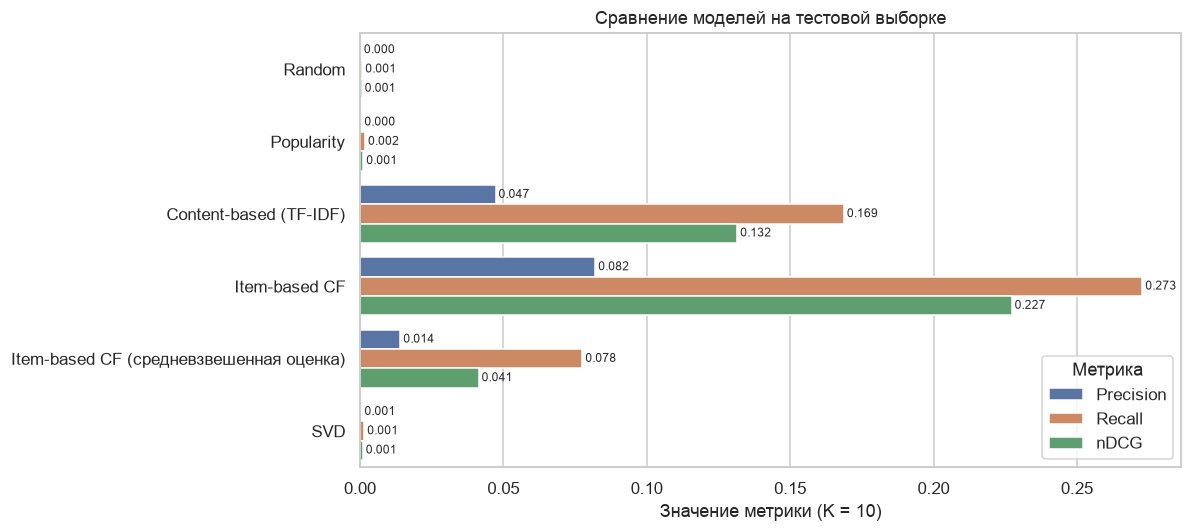

In [7]:
plot_data = (
    metrics["K = 10"]
    .reset_index(names="Модель")
    .melt(id_vars="Модель", var_name="Метрика", value_name="Значение")
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_data, y="Модель", x="Значение", hue="Метрика", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
ax.set_xlabel("Значение метрики (K = 10)")
ax.set_ylabel("")
ax.set_title("Сравнение моделей на тестовой выборке")
ax.legend(title="Метрика", loc="lower right")
plt.tight_layout()
plt.show()

## Качество в зависимости от длины истории

Посмотрим nDCG@10 отдельно для пользователей с короткой и длинной историей в train, чтобы увидеть проблему холодного старта.

In [8]:
history_len = np.asarray((train_matrix[eval_users - 1] > 0).sum(axis=1)).ravel()
groups = pd.cut(history_len, bins=[0, 3, 10, 30, 1000], labels=["1-3 оценки", "4-10", "11-30", "больше 30"])

by_history = pd.DataFrame({
    name: pd.Series(ndcg_at_k(get_hits(eval_users, recs, relevant_matrix), n_relevant, TOP_K)).groupby(groups, observed=True).mean()
    for name, recs in model_recs.items()
}).T
group_sizes = pd.Series(groups).value_counts()
by_history.columns = [f"{label} (n = {group_sizes[label]})" for label in by_history.columns]
by_history.columns.name = "Оценок в train"
by_history.round(4)

Оценок в train,1-3 оценки (n = 6484),4-10 (n = 12605),11-30 (n = 11914),больше 30 (n = 6965)
Random,0.0004,0.0004,0.0006,0.0012
Popularity,0.0013,0.0007,0.0014,0.0013
Content-based (TF-IDF),0.1376,0.1354,0.1224,0.1345
Item-based CF,0.1997,0.2203,0.2305,0.2598
Item-based CF (средневзвешенная оценка),0.0811,0.0467,0.0262,0.0207
SVD,0.0004,0.0006,0.0013,0.0018


## Выводы по сравнению

Лучше всех с большим отрывом работает Item-based CF. В среднем из 10 рекомендаций 0.8 оказываются книгами,
которые пользователь действительно высоко оценил в тесте, и модель находит около 27% таких книг.
Это много, если учесть, что выбирать приходится из 10 тысяч книг, а у половины пользователей в тесте одна-две релевантные книги.
Модель работает, потому что в данных много связанных книг (серии, один автор, один жанр).
Тот, кто оценил одну книгу серии, с большой вероятностью оценил и другую.

На втором месте контентная модель. Она ловит ту же структуру (серии и жанры) через теги и названия,
но не знает, какие из похожих книг на самом деле читают вместе. При этом оценки других пользователей ей не нужны совсем.

Сильно влияет способ ранжирования. Тот же Item-based CF с ранжированием по средневзвешенной предсказанной
оценке теряет почти всё качество, потому что наверх попадают книги с одним слабым соседом, получившим пятёрку.

Popularity и SVD оказались на уровне случайных рекомендаций. Причины у них разные.
- Popularity. В этой версии датасета у каждой книги примерно одинаковое число оценок, то есть вероятность встретить
  любую книгу в тесте одна и та же. Популярность здесь не несёт информации, а средняя оценка книги не говорит о том,
  станет ли пользователь её читать. На полных данных Goodreads с настоящим перекосом популярности
  этот бейзлайн был бы намного сильнее.
- SVD. Модель обучалась предсказывать оценку для пары, которая уже есть в данных, и с этим справляется лучше всех
  (RMSE 0.83). Но она не отвечает на вопрос, какие книги пользователь выберет. В top-N попадают книги с самым высоким
  смещением $b_i$, почти одинаковые для всех, покрытие каталога около 1%. Получается, что низкий RMSE не гарантирует
  хорошего ранжирования.

Что касается длины истории, по Precision и Recall пользователей с разной историей сравнивать напрямую нельзя (у активных
больше релевантных книг в тесте). Но по nDCG видно, что Item-based CF полезен даже при 1-3 оценках в истории,
и с ростом истории качество растёт. Для пользователя совсем без истории ни одна из персональных моделей не работает.

У такой оценки есть ограничения. Разбиение случайное, а не по времени (меток времени нет), так что в train могли попасть
оценки, поставленные позже тестовых. Офлайн-метрики считают неудачей любую книгу без оценки в тесте, хотя она могла бы понравиться.
Надёжнее было бы проверить модели в A/B-тесте.